# CA2 - Data Preparation and Exploratory Data Analysis

**Project:** Predicting Orbital Decay of Low Earth Orbit Objects to Support Satellite Operators' Disposal Planning

**Student:** Oleksii Taranov (sba26106)

**Module:** Strategic Thinking

**GitHub:** https://github.com/sba26106-bit/strategic-think-ca1

## 1. Business understanding
Satellite operators must show that hardware left in low Earth orbit (LEO) will re-enter within **five years** after the mission ends (FCC, 2024; ESA, 2023). The final model will estimate the **remaining orbital lifetime** of an uncontrolled object from its current orbit and solar activity.

## 2. Data understanding

In [1]:
# Import libraries

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from scipy import stats

In [2]:
# Folders and settings used in the whole notebook

DATA = Path("data")                      # the data folder path
RAW = DATA / "raw"                       # original downloads - this notebook never changes them
TLE_DIR = RAW / "tle_history"            # raw orbit history: 68 yearly Parquet files
DISCOS_DIR = RAW / "discos_objects"      # raw DISCOSweb download: one JSON file per page
OUT = DATA / "processed" / "ca2"         # everything this notebook writes goes here
STAGE = OUT / "stage1"                   # weekly LEO records after the first preparation pass
PREP = OUT / "prepared"                  # final prepared records for modelling
FIG = Path("figures")                    # saved charts for the report

SATCAT_FILE = RAW / "celestrak_satcat_2026-10-04.csv"
SPACEWEATHER_FILE = RAW / "spaceweather_2026-10-04.csv"
NOAA_FILE = RAW / "noaa_predicted_solar_cycle_2026-10-04.json"
CATALOG_DATE = pd.Timestamp("2026-10-04")   # SATCAT snapshot date = end of observation (censoring date)

R_EARTH = 6378.137        # Earth radius (km)
MU = 398600.4418          # Earth's gravitational parameter (km^3/s^2)
LEO_MAX_KM = 2000         # LEO upper limit: apogee must be at or below this height
MIN_PERIGEE_KM = 80       # records with a lower perigee are bad orbit fits
SEED = 42                 # fixed random seed, so samples and splits can be reproduced

for folder in [STAGE, PREP]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

raw_files = sorted(TLE_DIR.glob("tle_*.parquet"))
print(f"Data folder: {DATA.resolve()}")
print(f"Raw orbit history files: {len(raw_files)}")
print(f"DISCOSweb pages: {len(list(DISCOS_DIR.glob('page_*.json')))}")
print(f"SATCAT found: {SATCAT_FILE.exists()} | Space weather found: {SPACEWEATHER_FILE.exists()} | "
      f"NOAA forecast found: {NOAA_FILE.exists()}")

Data folder: C:\Users\oleks\Documents\CCT College Dublin\Strategical thinking\CA2\Submission\data
Raw orbit history files: 68
DISCOSweb pages: 933
SATCAT found: True | Space weather found: True | NOAA forecast found: True


### 2.1 Sources

The sources used in this project are listed below. The amounts are the **expected (approximate)** sizes, taken from the source descriptions and the download step. The exact numbers of rows and objects are calculated with Python in the next section.

| Source | File | Content | Expected amount | Permission | Used in |
|---|---|---|---|---|---|
| Space-Track.org orbit history, via a public Parquet copy (Simon, 2026) | data/raw/tle_history/ | Orbital elements, drag term and decay rate for every tracked object, 1959-2026 | About 239.5 million records in 68 yearly files (about 12.5 GB) | Basic data redistributable with citation (Space-Track.org, 2026); copy under CC BY 4.0 licence | CA2 |
| CelesTrak SATCAT (CelesTrak, 2026a) | data/raw/celestrak_satcat_2026-10-04.csv | Object type, status, size class, launch and re-entry dates | About 70,000 catalogued objects since 1957 | Free public data; the CelesTrak usage policy is followed; CelesTrak and the original providers are cited | CA2 |
| CelesTrak space weather (CelesTrak, 2026b) | data/raw/spaceweather_2026-10-04.csv | Daily F10.7 solar flux, Kp/Ap indices, sunspot number | About 25,000 daily rows since October 1957 | Free public data; CelesTrak and the original providers are cited | CA2 |
| ESA DISCOSweb (European Space Agency, 2026) | data/raw/discos_objects/ | Mass, cross-section and initial orbits of catalogued objects, including fragmentation debris | About 93,000 objects | Registered account;<br>ESA DISCOSweb is cited;<br>raw data is not republished | CA2 |
| NOAA solar-cycle forecast (NOAA Space Weather Prediction Center, 2026) | data/raw/noaa_predicted_solar_cycle_2026-10-04.json | Predicted monthly F10.7 and sunspot number | Monthly values for the current solar cycle | US government work (public domain);<br>NOAA Space Weather Prediction Center is cited | CA2 (described only); used for predictions in Semester 2 |
| GCAT (McDowell, 2020) | data/raw/gcat_satcat_2026-10-04.tsv | Independent mass and size estimates for cross-checking;<br>payload end-of-life data | About 70,000 catalogued objects | Creative Commons CC-BY licence;<br>GCAT is cited | Semester 2 (optional) |

The orbit history, SATCAT, space weather and DISCOSweb are prepared and explored in this notebook. The NOAA forecast contains **predicted** solar activity, so it is not used to build the training data; it is described here and will be used when the model predicts future re-entries. GCAT is kept as an optional cross-check for missing mass and size values in Semester 2.

### 2.2 Orbit history - exact size and structure
The number of records is read from each file's metadata, so the 12.5 GB of data does not need to be loaded. The number of distinct objects is counted from the `norad_id` column only.

Raw orbit history: 251,312,863 records | 68,197 distinct objects | 68 files | 12.5 GB


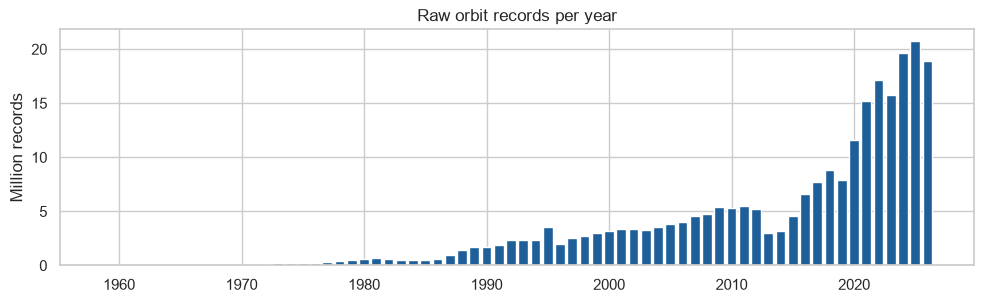

,records,objects,size_MB
year,,,
2022,17139087,27607,861.1
2023,15740029,28194,789.6
2024,19654504,29542,979.0
2025,20779646,31711,1035.6
2026,18937812,32842,730.9


In [3]:
raw_size = []
for f in raw_files:
    ids = pd.read_parquet(f, columns=["norad_id"])["norad_id"]
    raw_size.append({"year": int(f.stem[-4:]), "records": pq.ParquetFile(f).metadata.num_rows,
                     "objects": ids.nunique(), "size_MB": round(f.stat().st_size / 1e6, 1)})
raw_size = pd.DataFrame(raw_size).set_index("year")

all_ids = set()
for f in raw_files:
    all_ids.update(pd.read_parquet(f, columns=["norad_id"])["norad_id"].unique())

print(f"Raw orbit history: {raw_size['records'].sum():,} records | {len(all_ids):,} distinct objects | "
      f"{len(raw_files)} files | {raw_size['size_MB'].sum() / 1000:.1f} GB")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(raw_size.index, raw_size["records"] / 1e6, color="#1f5f99")
ax.set(title="Raw orbit records per year", xlabel="", ylabel="Million records")
fig.tight_layout(); fig.savefig(FIG / "fig_raw_records.png", dpi=150); plt.show()
raw_size.tail()

In [4]:
# Structure of the raw records: column types and the first rows of the latest file
example = next(pq.ParquetFile(raw_files[-1]).iter_batches(batch_size=5)).to_pandas()
print(example.dtypes.to_string())
example

norad_id                         int32
epoch              datetime64[us, UTC]
inclination                    float32
raan                           float32
eccentricity                   float32
arg_perigee                    float32
mean_anomaly                   float32
mean_motion                    float64
mean_motion_dot                float64
bstar                          float64
intl_designator                    str
altitude_km                    float32


,norad_id,epoch,inclination,raan,eccentricity,arg_perigee,mean_anomaly,mean_motion,mean_motion_dot,bstar,intl_designator,altitude_km
0,5,2026-01-01 08:22:35.059296+00:00,34.243698,109.205902,0.183993,106.250504,274.750702,10.859406,8.300000e-07,0.000125,58002B,657.969971
1,5,2026-01-02 15:16:44.336928+00:00,34.243999,105.231400,0.183991,112.055000,268.509003,10.859409,9.400000e-07,0.000138,58002B,657.989990
2,5,2026-01-03 08:56:13.002144+00:00,34.244099,102.960403,0.183989,115.371803,264.836487,10.859411,9.500000e-07,0.000137,58002B,658.000000
3,5,2026-01-03 15:33:30.820032+00:00,34.244099,102.108597,0.183989,116.615799,263.439087,10.859409,6.700000e-07,0.000102,58002B,658.000000
4,5,2026-01-04 07:00:31.442976+00:00,34.244099,100.121399,0.183987,119.518303,260.136292,10.859409,5.200000e-07,0.000082,58002B,658.020020


Each record is one orbit estimate (a "two-line element set") for one object at one time (`epoch`). The main fields are:
- `mean_motion` - revolutions per day; it gives the size of the orbit (semi-major axis),
- `eccentricity` - how elongated the orbit is; with the semi-major axis it gives perigee and apogee height,
- `inclination` - the tilt of the orbit,
- `bstar` - a fitted drag term, and `mean_motion_dot` - how fast the orbit is shrinking.

The exact count is higher than the expected 239.5 million in the source description, so the exact numbers are used from here on.

### 2.3 SATCAT - object types and re-entries

In [5]:
satcat = pd.read_csv(SATCAT_FILE, parse_dates=["LAUNCH_DATE", "DECAY_DATE"])
satcat["status"] = np.where(satcat["DECAY_DATE"].notna(), "re-entered", "in orbit")

print(f"{len(satcat):,} catalogued objects | duplicated NORAD numbers: {satcat['NORAD_CAT_ID'].duplicated().sum()}")
print(f"Missing values: {satcat[['OBJECT_TYPE', 'OPS_STATUS_CODE', 'DECAY_DATE', 'RCS']].isna().sum().to_dict()}")
pd.crosstab(satcat["OBJECT_TYPE"], satcat["status"], margins=True)

70,882 catalogued objects | duplicated NORAD numbers: 0
Missing values: {'OBJECT_TYPE': 0, 'OPS_STATUS_CODE': 16524, 'DECAY_DATE': 35229, 'RCS': 37951}


status,in orbit,re-entered,All
OBJECT_TYPE,,,
DEB,12533,23375,35908
PAY,20209,7691,27900
R/B,2431,4477,6908
UNK,56,110,166
All,35229,35653,70882
